<a href="https://colab.research.google.com/github/jakob-steuer/CSA_2026/blob/main/hpc_exercise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HPC hands-on: scaling, balancing and scheduling

~60 minutes · no cluster needed · you only run cells and move sliders

| Part | Question | Time |
|---|---|---|
| 1 | What does "running in parallel" mean — and does it always help? | 10 min |
| 2 | Why are 100 cores not 100× faster? | 10 min |
| 3 | How do you share uneven work fairly? | 10 min |
| 4 | How does a cluster decide whose job runs when? | 12 min |
| 5 | Your own code: the biggest lever of all | 15 min |

**How it works:** run the cells top to bottom (`Shift + Enter`). 🎯 marks a question: **guess first, then run.**
Solutions are hidden behind 🔍 — try before you peek. Cells marked **(bonus)** can be skipped if you are short on time.

#### Words you will meet

| Word | Meaning |
|---|---|
| **core** | one calculation unit of a processor (CPU) |
| **node** | one computer of the cluster; it contains many cores |
| **task** | one piece of work, e.g. "analyse image no. 17" |
| **worker** | one process on one core that works through tasks |
| **job** | what you hand to the cluster: a program plus the resources it asks for |
| **walltime** | the time limit you request for a job (the cluster stops it at that limit) |
| **queue / scheduler** | the waiting list of jobs / the program that decides who runs where and when |

In [1]:
#@title Setup (run me first)
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact, fixed

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})


def slider(value, lo, hi, step, label):
    kind = widgets.IntSlider if isinstance(value, int) and isinstance(step, int) else widgets.FloatSlider
    return kind(value=value, min=lo, max=hi, step=step, description=label, continuous_update=False,
                style={"description_width": "initial"}, layout=widgets.Layout(width="480px"))

---
## Part 1 — What does "running in parallel" mean?

* **Serial:** one worker does all the tasks, one after the other.
* **Parallel:** the work is split up and several workers process their share *at the same time*.
* **Speedup** = time with 1 worker ÷ time with *N* workers. Ideally *N* workers give *N*× speedup.

**Our example:** estimate π by throwing random darts at a square. The share of darts that land inside the quarter circle is π/4.
Every dart is independent of all the others, so we can simply **split the darts among several workers**.

Colab gives you only **2 CPU cores**, so real speedups stop at 2×. That is fine — Parts 2–4 explore what happens with 100 or 1000 cores.

In [2]:
#@title Helper code for Part 1 (run me, no need to read)
import os, time, random, importlib
from multiprocessing import Pool

# the worker functions live in a small file so that the worker processes can import them
open("hpc_workers.py", "w").write('''
import random
import numpy as np

def count_python(args):
    """Throw n darts at the unit square with a plain Python loop, count hits in the quarter circle."""
    n, seed = args
    rnd = random.Random(seed)
    inside = 0
    for _ in range(n):
        x, y = rnd.random(), rnd.random()
        if x * x + y * y <= 1.0:
            inside += 1
    return inside

def count_numpy(args):
    """Same experiment, but vectorised with NumPy (in chunks of one million darts)."""
    n, seed = args
    rng = np.random.default_rng(seed)
    inside, left = 0, n
    while left > 0:
        m = min(left, 1_000_000)
        x, y = rng.random(m), rng.random(m)
        inside += int(np.count_nonzero(x * x + y * y <= 1.0))
        left -= m
    return inside
''')
importlib.invalidate_caches()
import hpc_workers
importlib.reload(hpc_workers)


def run_pi(n_samples, workers, method):
    """Estimate pi with the given number of worker processes. Returns (pi, seconds)."""
    func = hpc_workers.count_python if method == "python" else hpc_workers.count_numpy
    tasks = [(n_samples // workers, seed) for seed in range(workers)]
    start = time.perf_counter()
    if workers == 1:
        hits = [func(tasks[0])]
    else:
        with Pool(workers) as pool:                  # starting the pool is part of the cost!
            hits = pool.map(func, tasks)
    seconds = time.perf_counter() - start
    return 4 * sum(hits) / (workers * (n_samples // workers)), seconds


def measure(n_samples=2_000_000, workers=(1, 2, 4), method="python"):
    print(f"This machine has {os.cpu_count()} CPU cores.  Method: {method}, {n_samples:,} random darts.\n")
    times = []
    for w in workers:
        pi, t = run_pi(n_samples, w, method)
        times.append(t)
        print(f"  {w:>2} worker(s): {t:6.2f} s   speedup {times[0] / t:4.2f}x   (pi is about {pi:.4f})")
    fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
    ax[0].bar([str(w) for w in workers], times, color="C0")
    ax[0].set(xlabel="workers", ylabel="time [s]", title="Wall-clock time")
    ax[1].plot(workers, workers, "--", color="grey", label="ideal")
    ax[1].plot(workers, [times[0] / t for t in times], "o-", color="C0", label="measured")
    ax[1].set(xlabel="workers", ylabel="speedup", title="Speedup = time(1) / time(N)")
    ax[1].legend()
    for a in ax:
        a.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

**1a** 🎯 How much faster will 2 workers be than 1? And 4 workers?

This machine has 2 CPU cores.  Method: python, 5,000,000 random darts.

   1 worker(s):   2.53 s   speedup 1.00x   (pi is about 3.1415)
   2 worker(s):   2.88 s   speedup 0.88x   (pi is about 3.1421)
   4 worker(s):   2.01 s   speedup 1.26x   (pi is about 3.1409)


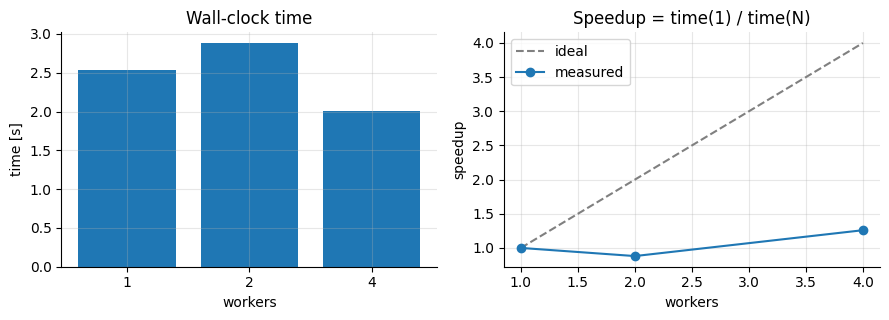

In [3]:
measure(n_samples=5_000_000, workers=(1, 2, 4), method="python")

<details>
<summary>🔍 Solution</summary>

On Colab (2 cores): about **1.8–1.9×** with 2 workers, and **no further gain with 4** — there are only 2 cores to run on.
Not exactly 2×, because starting the workers and collecting the results costs time (communication overhead — Part 2).
On a laptop with more cores the curve keeps climbing for longer.

</details>

**1b** 🎯 Same experiment with only 20 000 darts. What happens?

This machine has 2 CPU cores.  Method: python, 20,000 random darts.

   1 worker(s):   0.01 s   speedup 1.00x   (pi is about 3.1480)
   2 worker(s):   0.06 s   speedup 0.17x   (pi is about 3.1384)
   4 worker(s):   0.08 s   speedup 0.12x   (pi is about 3.1540)


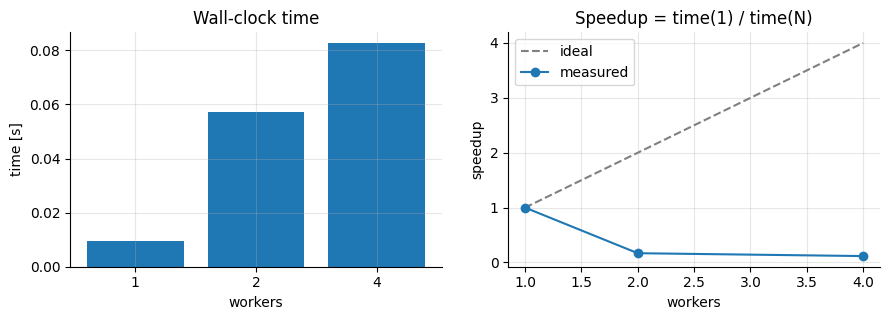

In [4]:
measure(n_samples=20_000, workers=(1, 2, 4), method="python")

<details>
<summary>🔍 Solution</summary>

Parallel is **slower** than serial (speedup < 1). The actual work takes a few milliseconds, but starting a worker takes far longer.
Parallelising pays off only when each worker gets enough work — one reason to run test jobs on small data *serially*.

</details>

**1c (bonus)** The Python loop handles one dart at a time. NumPy handles a million darts per call ("vectorised").
🎯 With 10× more darts, is it still faster than the plain Python loop? By how much, roughly?

This machine has 2 CPU cores.  Method: numpy, 50,000,000 random darts.

   1 worker(s):   3.77 s   speedup 1.00x   (pi is about 3.1415)
   2 worker(s):   1.43 s   speedup 2.63x   (pi is about 3.1415)


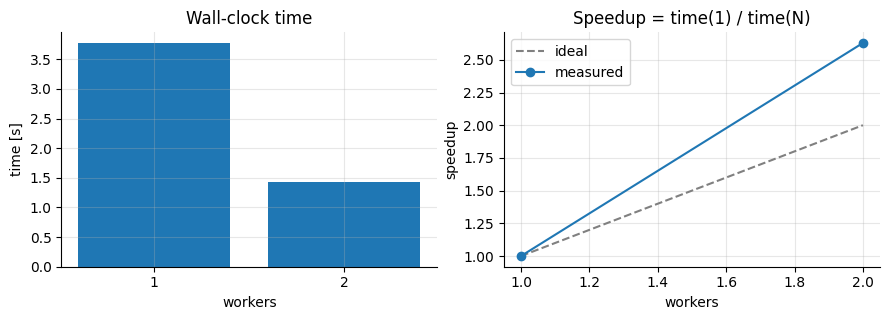

In [5]:
measure(n_samples=50_000_000, workers=(1, 2), method="numpy")

<details>
<summary>🔍 Solution</summary>

NumPy handles **10× more darts** in about the same time or less than the Python loop needs for 1× — i.e. well over 10× faster per dart on a single core (the exact factor depends on the machine).
Note also that with NumPy, 2 workers give a smaller gain: there is less work per worker, so the start-up overhead weighs more.

</details>

**In short:** parallel workers can speed things up, but (1) there must be enough work per worker, (2) starting and coordinating workers costs time, and (3) before buying more cores, check whether the code itself is wasteful — *time = energy*.

---
## Part 2 — Why are 100 cores not 100× faster?

In Part 1, 2 workers gave less than 2×. With many more workers the gap grows. Here is a small model of a job that takes **1000 h on one core**:

> runtime on *N* cores = **serial part** + **parallel part ÷ N** + **communication cost × N**

* *serial part:* cannot be split up (reading the input, setting up, writing results) — it takes the same time however many cores you have
* *parallel part:* splits perfectly among the cores
* *communication:* workers have to exchange data and wait for each other; this grows with the number of workers

**Two ways to use more cores**
* **Strong scaling:** same problem, more cores → *faster*.
* **Weak scaling:** the problem grows with the cores (2× cores, 2× larger grid) → *same runtime, bigger problem*.

**The three plots:** *speedup* (time with 1 core ÷ time with N cores), *efficiency* (speedup ÷ N: how much of each core you really use), and *core-hours* (cores × runtime: what you are charged — and roughly proportional to the energy used). The red dot marks the best speedup.

In [6]:
#@title Helper code for Part 2 (run me, no need to read)
def runtime(N, serial_fraction, comm_cost, T1=1000.0):
    """Runtime (hours) on N cores for a job that takes T1 hours on 1 core."""
    N = np.asarray(N, dtype=float)
    return T1 * (serial_fraction + (1 - serial_fraction) / N + comm_cost / 100 * (N - 1))


def scaling_plot(serial_fraction_pct=0.0, comm_cost=0.02, mode="strong"):
    s = serial_fraction_pct / 100
    N = np.unique(np.round(np.logspace(0, 3, 200)).astype(int))   # 1 ... 1000 cores
    T1 = 1000.0
    if mode == "strong":      # same problem, more cores
        T = runtime(N, s, comm_cost, T1)
        speedup = T1 / T
    else:                     # problem grows with the number of cores
        T = T1 * (1 + comm_cost / 100 * (N - 1))
        speedup = (s + (1 - s) * N) / (1 + comm_cost / 100 * (N - 1))
    efficiency = speedup / N
    best = N[np.argmax(speedup)]

    fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
    ax[0].plot(N, N, "--", color="grey", label="ideal")
    ax[0].plot(N, speedup, color="C0", lw=2, label="your model")
    ax[0].plot(best, speedup.max(), "o", color="C3")
    ax[0].set(xscale="log", yscale="log", xlabel="cores", ylabel="speedup", title="Speedup")
    ax[0].legend()
    ax[1].plot(N, 100 * efficiency, color="C2", lw=2)
    ax[1].axhline(70, ls=":", color="grey")
    ax[1].set(xscale="log", ylim=(0, 105), xlabel="cores", ylabel="efficiency [%]",
              title="Parallel efficiency (speedup / cores)")
    if mode == "strong":
        ax[2].plot(N, N * T, color="C1", lw=2)
        ax[2].axhline(T1, ls="--", color="grey")
        ax[2].set(xscale="log", yscale="log", xlabel="cores", ylabel="core-hours",
                  title="Resources paid (cores x runtime)")
    else:
        ax[2].plot(N, T, color="C1", lw=2)
        ax[2].axhline(T1, ls="--", color="grey")
        ax[2].set(xscale="log", ylim=(0, 1.5 * max(T1, T.max())), xlabel="cores", ylabel="runtime [h]",
                  title="Runtime (ideal: stays flat)")
    for a in ax:
        a.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    i = np.argmax(speedup)
    if mode == "strong":
        print(f"Best speedup: {speedup[i]:.1f}x at {N[i]} cores "
              f"(efficiency {100 * efficiency[i]:.0f} %, {N[i] * T[i]:.0f} core-hours instead of {T1:.0f})")
    else:
        print(f"At {N[-1]} cores the problem is {N[-1]}x bigger, but the runtime is "
              f"{T[-1] / T1:.2f}x the original runtime (efficiency {100 * efficiency[-1]:.0f} %)")

In [7]:
interact(scaling_plot,
         serial_fraction_pct=slider(0.0, 0, 20, 0.5, "serial part of the code [%]"),
         comm_cost=slider(0.02, 0, 0.5, 0.01, "communication cost per extra core [% of T1]"),
         mode=widgets.ToggleButtons(options=["strong", "weak"], description="scaling"));

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='serial part of the code [%]…

**2a** 🎯 With the default sliders (no serial part, small communication cost): how many cores give the best speedup — and what happens beyond that?

<details>
<summary>🔍 Solution</summary>

Best speedup **≈ 36× at ≈ 70 cores** (the example from the slides: 100 cores give ≈ 33×, not 100×).
Beyond that, communication costs more than the extra cores save, and the job gets **slower**.

</details>

**2b** 🎯 Set communication to 0 and the serial part to 5 %. What is the maximum speedup, however many cores you throw at it?

<details>
<summary>🔍 Solution</summary>

**20×** (= 1 / 0.05). The serial 5 % never gets faster — this is *Amdahl's law*. A 1 % serial part caps you at 100×.

</details>

**2c** 🎯 Back to the defaults. You may request cores in Slurm: which number would you pick, looking at all three plots?

<details>
<summary>🔍 Solution</summary>

A common rule of thumb: stay where efficiency is **≥ 70 %** — here about **45 cores**: ≈ 33× speedup for ≈ 1430 core-hours.
The "best" 71 cores give just 36× but cost ≈ 2000 core-hours: **~40 % more resources and energy for 10 % more speed.**
This is why you run a small scaling test before a big job.

</details>

**2d** 🎯 Switch to **weak** scaling and set the serial part to 5 %. What is different?

<details>
<summary>🔍 Solution</summary>

No hard ceiling any more: with 1000 cores the problem is 1000× larger and the runtime only ≈ 1.2× the original.
Weak scaling is why big machines are useful even though Amdahl's law limits any single problem (*Gustafson's law*).
The question changes from "how fast?" to "how big a problem can I solve in the same time?".

</details>

**In short:** speedup is limited by the serial part and by communication. More cores cost more energy than they save time once efficiency drops — pick the core count by efficiency, not by maximum speedup, and test on a small scale first.

---
## Part 3 — How do you share uneven work fairly?

**Picture a kitchen** with 8 cooks and 60 dishes to prepare. A salad takes 2 minutes, a roast takes an hour. The meal is only ready when the **slowest cook** is finished, so a cook who finishes early and stands around waiting is wasted capacity.

In HPC: the *cooks* are **workers**, the *dishes* are **tasks**. A real example: analysing 60 microscopy images, where later images contain more cells and take longer.

Three ways to hand out the work:
* **static blocks:** the list is cut into 8 consecutive blocks up front — cook 1 gets dishes 1–8, cook 2 gets 9–16, … (the last cook gets all the complicated dishes)
* **round robin:** dishes are dealt out like cards — dish 1 to cook 1, dish 2 to cook 2, …, then start over
* **dynamic:** all dishes lie in one pile; whichever cook is free takes the next one

**How to read the chart:** each row is one worker; each coloured block is one task and its length is the time it takes. **Empty space at the end of a row = that worker is done and idle**, waiting for the others. The **red line** marks when the whole job is finished; the **dashed line** is where it would finish if everybody had exactly the same amount of work.

In [8]:
#@title Helper code for Part 3 (run me, no need to read)
import heapq


def make_tasks(n_tasks=60, skew=1.0, seed=1):
    """Task durations. Later tasks tend to be longer (e.g. bigger images / finer grid cells)."""
    rng = np.random.default_rng(seed)
    base = rng.lognormal(mean=0.0, sigma=0.6 * skew, size=n_tasks)
    trend = np.linspace(0.5, 1.5, n_tasks) ** (2 * skew)
    return base * trend


def schedule(durations, n_workers, strategy, chunk=1, fetch_cost=0.0):
    """Returns a list of (worker, start, duration, task_id)."""
    n = len(durations)
    jobs = []
    if strategy in ("static blocks", "round robin"):
        if strategy == "static blocks":
            owner = np.repeat(np.arange(n_workers), int(np.ceil(n / n_workers)))[:n]
        else:
            owner = np.arange(n) % n_workers
        t = np.zeros(n_workers)
        for i in range(n):
            w = owner[i]
            jobs.append((w, t[w], durations[i], i))
            t[w] += durations[i]
    else:                                   # dynamic: whoever is free grabs the next chunk
        order = np.arange(n)
        if strategy == "dynamic, longest first":
            order = np.argsort(-durations)
        free = [(0.0, w) for w in range(n_workers)]
        heapq.heapify(free)
        for k in range(0, n, chunk):
            t, w = heapq.heappop(free)
            t += fetch_cost
            for i in order[k:k + chunk]:
                jobs.append((w, t, durations[i], i))
                t += durations[i]
            heapq.heappush(free, (t, w))
    return jobs


def balancing_plot(n_workers=8, skew=1.0, chunk=1, fetch_cost=0.0, seed=1,
                   strategies=("static blocks", "round robin", "dynamic")):
    d = make_tasks(60, skew, seed)
    fig, axes = plt.subplots(len(strategies), 1, figsize=(11, 2.3 * len(strategies)), sharex=True)
    axes = np.atleast_1d(axes)
    ideal = d.sum() / n_workers
    for ax, strat in zip(axes, strategies):
        jobs = schedule(d, n_workers, strat, chunk, fetch_cost)
        for w, start, dur, i in jobs:
            ax.barh(w, dur, left=start, color=plt.cm.viridis(i / len(d)), edgecolor="white", lw=0.5)
        makespan = max(s + dur for _, s, dur, _ in jobs)
        ax.axvline(makespan, color="C3", lw=2)
        ax.axvline(ideal, color="grey", ls="--")
        busy = d.sum() / (makespan * n_workers)
        ax.set(ylabel="worker", yticks=range(n_workers),
               title=f"{strat}: finished after {makespan:.0f}  |  workers busy {100 * busy:.0f} % of the time")
        ax.invert_yaxis()
    axes[-1].set_xlabel("time   (red = finish time, dashed = perfect balance; colour = task number)")
    plt.tight_layout()
    plt.show()

In [9]:
interact(balancing_plot,
         n_workers=slider(8, 2, 16, 1, "workers (cooks)"),
         skew=slider(1.0, 0, 2, 0.25, "how different the task lengths are"),
         seed=slider(1, 1, 9, 1, "random set of tasks"),
         chunk=fixed(1), fetch_cost=fixed(0.0),
         strategies=fixed(("static blocks", "round robin", "dynamic")));

interactive(children=(IntSlider(value=8, continuous_update=False, description='workers (cooks)', layout=Layout…

**3a** 🎯 Which strategy finishes first? Then set "how different the task lengths are" to 0 — what changes?

<details>
<summary>🔍 Solution</summary>

*Dynamic* wins (≈ 10.4 vs 12.5 round robin vs 17.7 static blocks, for the default settings; perfect balance would be ≈ 8.8).
Static blocks are bad here because later tasks are longer — the last worker is still busy while the first sits idle (≈ 50 % utilisation).
With "different" = 0 all strategies are equal: balancing only matters when work is uneven.

</details>

**3b** Dynamic is not free: every time a worker walks to the pile and takes a task, that costs a little time (in a program: asking a central process for work). Taking **several tasks at once** (a "chunk") means fewer trips but a worse balance.
🎯 If one trip costs 0.5 (a short task takes about 1), which chunk size finishes first?

In [10]:
interact(balancing_plot,
         chunk=slider(1, 1, 30, 1, "tasks per trip (chunk size)"),
         fetch_cost=slider(0.5, 0, 2, 0.1, "cost of one trip"),
         n_workers=fixed(8), skew=fixed(1.0), seed=fixed(1),
         strategies=fixed(("static blocks", "dynamic")));

interactive(children=(IntSlider(value=1, continuous_update=False, description='tasks per trip (chunk size)', l…

<details>
<summary>🔍 Solution</summary>

A small chunk of **2** is best (≈ 13.3, versus ≈ 14.2 for chunk 1). With large chunks (30 tasks = just two chunks) dynamic degrades into static blocks (≈ 53).
Trade-off: **balance quality vs. overhead** — the same kind of trade-off as in Part 2.

</details>

**3c (bonus)** If you know roughly how long each task takes, hand out the **longest ones first**.
🎯 How close to perfect balance (dashed line) do you get?

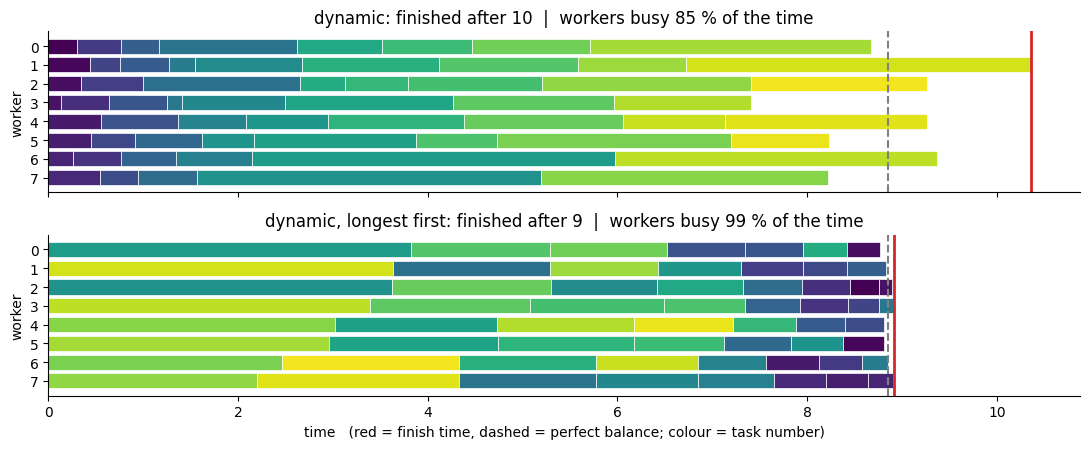

In [11]:
balancing_plot(strategies=("dynamic", "dynamic, longest first"))

<details>
<summary>🔍 Solution</summary>

Almost perfect: ≈ 8.9 vs. 8.8 ideal. Long tasks first, short tasks fill the gaps at the end (like packing big items into a suitcase first).
In practice you rarely know task lengths exactly — but an estimate (file size, grid size) is often good enough.

</details>

**In short:** if tasks differ in length, a fixed split in advance leaves workers idle. Handing out work on demand (dynamic) fixes this, at the price of some coordination overhead — and idle workers still burn energy.

---
## Part 4 — How does a cluster decide whose job runs when?

Many users share one cluster. You do not simply start your program: you **submit a job** and state how many **nodes** you need and for how long (the **walltime**). The **scheduler** keeps a **queue** and plays *Tetris* with the jobs.

**How to read the picture:** time runs left → right, the rows are the nodes of a small cluster with **8 nodes**. A job is a block: *tall* = many nodes, *wide* = long walltime. Grey hatched areas are **idle nodes** — capacity nobody uses, but that still burns energy.

**Our queue.** Everybody submitted at t = 0, in this order:

| Job | Nodes | Time | |
|---|---|---|---|
| A | 3 | 6 h | |
| B | 8 | 3 h | needs the *whole* cluster |
| C | 1 | 2 h | |
| D | 1 | 3 h | |
| E | 1 | 4 h | |
| **YOU** | 2 | really 2.5 h — you ask for **3 h** | |

**Two ways to run the queue**
* **fifo** (first in, first out): strictly in order. Nobody may overtake. B has to wait until A is finished and the whole cluster is free — and C, D, E, YOU wait behind B.
* **backfill:** B still gets its place at the front, but a *later* job may jump ahead **if it fits into a gap and is guaranteed to finish before B is due to start**. The scheduler can only check this against the walltime users **requested** — it cannot know how long a job will really take.

In [12]:
#@title Helper code for Part 4 (run me, no need to read)
def simulate(jobs, n_nodes, policy="backfill"):
    """Tiny batch scheduler. policy: 'fifo' or 'backfill' (EASY backfilling, as in Slurm)."""
    jobs = sorted(jobs, key=lambda j: j["submit"])
    pending, running, t, k = [], [], 0.0, 0
    free_nodes = set(range(n_nodes))
    while k < len(jobs) or pending or running:
        started = True
        while started and pending:                  # start whatever can start now
            started = False
            head = pending[0]
            to_start = None
            if head["nodes"] <= len(free_nodes):
                to_start = head
            elif policy == "backfill":
                # when will the first job in the queue get its nodes? (the scheduler only knows *requested* times)
                ends = sorted((r["t_start"] + r["req"], r["nodes"]) for r in running)
                avail, shadow = len(free_nodes), None
                for end, n in ends:
                    avail += n
                    if avail >= head["nodes"]:
                        shadow, spare = end, avail - head["nodes"]
                        break
                for j in pending[1:]:               # may a later job jump ahead without delaying the first one?
                    if j["nodes"] <= len(free_nodes) and (t + j["req"] <= shadow or j["nodes"] <= spare):
                        to_start = j
                        break
            if to_start is not None:
                pending.remove(to_start)
                to_start["t_start"] = t
                to_start["node_ids"] = sorted(free_nodes)[:to_start["nodes"]]
                free_nodes -= set(to_start["node_ids"])
                running.append(to_start)
                started = True
        t_submit = jobs[k]["submit"] if k < len(jobs) else np.inf
        t_end = min((r["t_start"] + r["real"] for r in running), default=np.inf)
        t = min(t_submit, t_end)
        while k < len(jobs) and jobs[k]["submit"] <= t:
            pending.append(jobs[k]); k += 1
        for r in [r for r in running if r["t_start"] + r["real"] <= t + 1e-9]:
            running.remove(r)
            free_nodes |= set(r["node_ids"])
            r["wait"] = r["t_start"] - r["submit"]
    return jobs


# ---------------------------------------------------------------- the small, hand-made example
TOY_NODES = 8
# name, nodes, hours (really needed = requested), all submitted at t = 0, in this order
TOY_JOBS = [("A", 3, 6), ("B", 8, 3), ("C", 1, 2), ("D", 1, 3), ("E", 1, 4)]
YOU_REAL = 2.5      # your job really needs 2.5 h


def toy_jobs(my_nodes, my_req):
    jobs = [dict(name=n, nodes=k, req=h, real=h, submit=0.0, who="other") for n, k, h in TOY_JOBS]
    jobs.append(dict(name="YOU", nodes=int(my_nodes), req=float(my_req), real=YOU_REAL, submit=0.0, who="me"))
    return jobs


def _draw_board(ax, policy, my_nodes, my_req):
    done = simulate(toy_jobs(my_nodes, my_req), TOY_NODES, policy)
    end = max(j["t_start"] + j["real"] for j in done)
    ax.add_patch(plt.Rectangle((0, 0), end, TOY_NODES, facecolor="#f2f2f2", hatch="///", edgecolor="#d0d0d0", lw=0))
    for j in done:
        ids = j["node_ids"]
        runs = np.split(ids, np.where(np.diff(ids) > 1)[0] + 1)           # consecutive node blocks
        colour = "#d62728" if j["who"] == "me" else "#4c8cc9"
        for run in runs:
            ax.add_patch(plt.Rectangle((j["t_start"], run[0]), j["real"], len(run), facecolor=colour,
                                       edgecolor="white", lw=2))
            if j["who"] == "me" and j["req"] > j["real"]:                  # reserved, but not used
                ax.add_patch(plt.Rectangle((j["t_start"] + j["real"], run[0]), j["req"] - j["real"], len(run),
                                           facecolor="none", edgecolor="#d62728", hatch="xx", lw=0.8, alpha=0.6))
        big = max(runs, key=len)
        ax.text(j["t_start"] + j["real"] / 2, big[0] + len(big) / 2, j["name"], ha="center", va="center",
                color="white", fontweight="bold")
    me = [j for j in done if j["who"] == "me"][0]
    idle = TOY_NODES * end - sum(j["nodes"] * j["real"] for j in done)
    ax.set(ylim=(TOY_NODES, 0), ylabel="node", yticks=range(0, TOY_NODES, 2))
    ax.set_title(f"{policy.upper()}:  YOU wait {me['wait']:.1f} h   |   all jobs done after {end:.1f} h   |   "
                 f"idle (grey hatched): {idle:.0f} node-hours", loc="left", fontsize=10)
    return max(end, me["t_start"] + me["req"]) + 0.3


def tetris_plot(my_nodes=2, my_req_hours=3.0, policy="both"):
    policies = ["fifo", "backfill"] if policy == "both" else [policy]
    fig, axes = plt.subplots(len(policies), 1, figsize=(10, 2.9 * len(policies)), sharex=True)
    axes = np.atleast_1d(axes)
    xmax = max(_draw_board(ax, p, my_nodes, my_req_hours) for ax, p in zip(axes, policies))
    axes[0].set_xlim(0, xmax)
    axes[-1].set_xlabel("time [h]   (all jobs are submitted at t = 0, in the order A, B, C, D, E, YOU)")
    plt.tight_layout()
    plt.show()


# ---------------------------------------------------------------- zooming out: a busy cluster, many random days
N_NODES = 16


def make_background(seed, overestimate=2.0, n_jobs=70, window=36.0):
    """Jobs of other users: (submit time, nodes, requested hours, real hours)."""
    rng = np.random.default_rng(seed)
    submit = np.sort(rng.uniform(0, window, n_jobs))
    nodes = rng.choice([1, 2, 4, 8, 16], size=n_jobs, p=[0.30, 0.25, 0.25, 0.15, 0.05])
    real = np.clip(rng.lognormal(0.3, 0.8, n_jobs), 0.25, 12)
    requested = real * rng.uniform(1.0, overestimate, n_jobs) if overestimate > 1 else real
    return [dict(submit=s, nodes=int(n), req=float(q), real=float(r), who="other")
            for s, n, q, r in zip(submit, nodes, requested, real)]


def my_job(nodes, req, real, submit=12.0):
    return dict(submit=submit, nodes=int(nodes), req=float(req), real=float(real), who="me")


def mean_over_seeds(my_nodes, my_req, my_real, policy, overestimate=2.0, seeds=range(25)):
    waits = []
    for s in seeds:
        done = simulate(make_background(s, overestimate) + [my_job(my_nodes, my_req, my_real)], N_NODES, policy)
        waits.append([j for j in done if j["who"] == "me"][0]["wait"])
    return np.mean(waits)


def wait_vs_request_plot(overestimate=2.0):
    reqs = np.array([3, 4, 6, 8, 12, 16, 24, 36])
    plt.figure(figsize=(6, 3.8))
    for policy, c in [("fifo", "grey"), ("backfill", "C0")]:
        plt.plot(reqs, [mean_over_seeds(4, r, 3.0, policy, overestimate) for r in reqs], "o-", color=c, label=policy)
    plt.xlabel("walltime you request [h]   (the job really needs 3 h)")
    plt.ylabel("average wait [h]")
    plt.title("Average over 25 random days on a busy cluster")
    plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()


def turnaround_vs_nodes_plot(serial_pct=5, overestimate=2.0):
    s = serial_pct / 100
    nodes = np.array([1, 2, 4, 8, 16])
    run = 24 * (s + (1 - s) / nodes)                      # 24 node-hours of work, Amdahl
    wait = np.array([mean_over_seeds(n, 1.2 * r, r, "backfill", overestimate) for n, r in zip(nodes, run)])
    plt.figure(figsize=(6, 3.8))
    plt.bar(range(5), run, label="running", color="C0")
    plt.bar(range(5), wait, bottom=run, label="waiting in the queue", color="C1")
    plt.xticks(range(5), nodes)
    plt.xlabel("nodes requested"); plt.ylabel("time to solution [h]")
    plt.title("Time to solution = waiting + running")
    plt.legend(); plt.tight_layout(); plt.show()

**4a** 🎯 Run both policies. Why do C, D, E and YOU start right away with *backfill*, and why not with *fifo*? Compare the grey hatched areas.

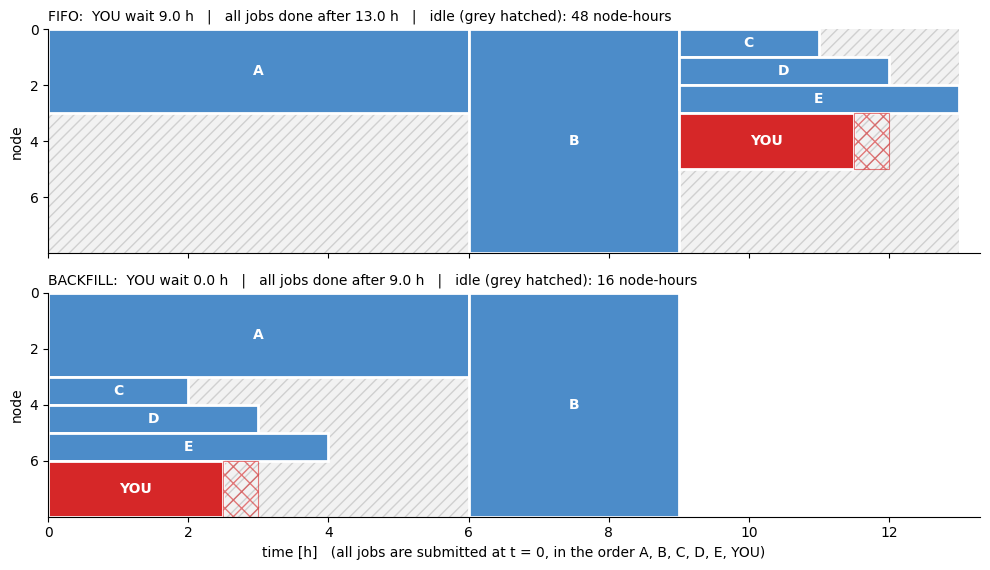

In [13]:
tetris_plot(my_nodes=2, my_req_hours=3.0, policy="both")

<details>
<summary>🔍 Solution</summary>

With *fifo*, A runs on 3 nodes, B needs all 8, so **5 nodes sit idle for 6 hours** while C, D, E and YOU wait behind B (YOU wait 9 h; 48 node-hours wasted).
With *backfill*, B is still due to start when A ends (t = 6 h). C, D, E and YOU are small enough to finish before that, so they use the idle nodes — and **B is not delayed at all**.
Result: YOU wait 0 h, everything is done at 9 h instead of 13 h, and only 16 node-hours are idle.

</details>

**4b** Now *you* are in control. 🎯 Set the walltime you request to 8 h — your job still really needs only 2.5 h. What happens, and why?
Then play with the number of nodes: what if you ask for 3 nodes instead of 2? Or 6?

In [14]:
interact(tetris_plot,
         my_nodes=slider(2, 1, 8, 1, "nodes you request"),
         my_req_hours=slider(3.0, 2.5, 12, 0.5, "walltime you request [h]"),
         policy=["backfill", "fifo", "both"]);

interactive(children=(IntSlider(value=2, continuous_update=False, description='nodes you request', layout=Layo…

<details>
<summary>🔍 Solution</summary>

* **8 h instead of 3 h:** your job is still the same 2.5 h, but now it is *"too long"* to fit into the gap before B starts (t = 6 h). The scheduler has to believe your request, so you wait behind B: **9 h instead of 0 h** — and the idle nodes stay unused for everyone. Over-requesting walltime hurts you *and* others. Request an honest estimate plus a margin (~20 %); the cluster kills the job at the limit.
* **3 nodes:** only 2 nodes are free at the start, so you wait until C finishes (2 h).
* **6 nodes:** the gap only has 5 nodes. You cannot fit, whatever your walltime: wait 9 h. Big requests wait longer.

</details>

**4c** A real cluster has hundreds of jobs and no neat picture, but the same effect shows up on average. Below: a busy 16-node cluster with random jobs from other users (who also over-request walltime), averaged over 25 random days.
🎯 Your job needs 3 h. What happens to your average waiting time as you request more walltime?

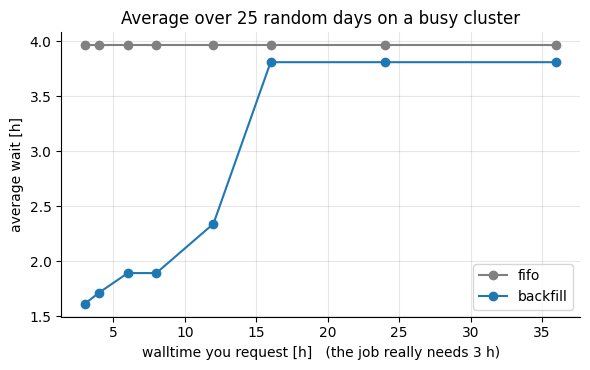

In [15]:
wait_vs_request_plot()

<details>
<summary>🔍 Solution</summary>

With *backfill* the average wait rises from ≈ 1.6 h (honest request) to ≈ 3.8 h (36 h requested): the less accurate your request, the fewer gaps you fit into.
It is still better than *fifo* (≈ 4 h, flat — fifo ignores the walltime because it never lets anybody overtake anyway).

</details>

**4d (bonus)** Your job needs 24 node-hours of work, with a 5 % serial part (Part 2). More nodes shorten the run — but big jobs wait longer. 🎯 How many nodes give the **shortest time to solution** (wait + run)?

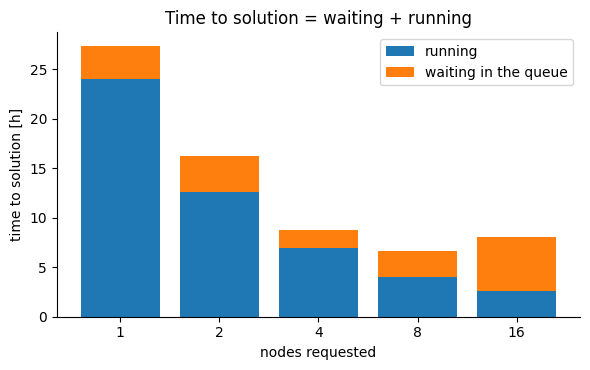

In [16]:
turnaround_vs_nodes_plot(serial_pct=5)

<details>
<summary>🔍 Solution</summary>

**8 nodes**, ≈ 6.6 h in total (4.1 h run + 2.5 h wait). 16 nodes run in 2.6 h but wait 5.4 h — slower overall, and wasteful (efficiency ≈ 58 %).
Change `serial_pct` to 0 or 20 and re-run: 8 nodes stays the best choice, but the total grows from ≈ 5 h to ≈ 10 h — and 16 nodes never wins.
**Ask for what you need, not for what exists.**

</details>

**In short:** the scheduler fills gaps (backfill) based on what you *request*, not what you *use*. An honest, right-sized request gets you through the queue faster and keeps the cluster busy for everyone.

---
## Part 5 — Your own code: the biggest lever of all

Parts 2–4 were about how to *run* code on a cluster: how many cores, how to share the work, how to request time. But the cluster cannot fix a **wasteful program** — and most first scripts are wasteful. Here is a typical one from the life sciences, written the way many of us write a first analysis script.

**The task.** A FASTA file contains many gene sequences (strings of the letters A, C, G, T). For each sequence we compute four features, e.g. as input for a classifier:

| Feature | Meaning |
|---|---|
| `gc_content` | share of G and C bases (varies between genome regions) |
| `cpg_count` | number of "CG" pairs (sites that can be methylated) |
| `tata_count` | number of "TATA" motifs (typical for promoters) |
| `longest_run` | longest stretch of one repeated base, e.g. AAAAAA (error-prone in sequencing) |

Real files also contain unknown bases (`N`) and soft-masked regions (lower case), so each sequence is **cleaned** first. The results are written to `features.csv`. Our data are random sequences of 3000 bases each — 500 of them for the speed tests.

In [17]:
#@title Helper code for Part 5 (run me, no need to read)
import os, re, csv, time
from multiprocessing import get_context


def make_fasta(n_seqs, length=3000, seed=7):
    """Write a FASTA file with random DNA sequences (some bases soft-masked or unknown, like real data)."""
    path = f"sequences_{n_seqs}.fasta"
    if os.path.exists(path):
        return path
    rng = np.random.default_rng(seed)
    letters = np.frombuffer(b"ACGT", dtype="S1")
    with open(path, "w") as f:
        for i in range(n_seqs):
            gc = rng.uniform(0.35, 0.60)
            cum = np.cumsum([(1 - gc) / 2, gc / 2, gc / 2, (1 - gc) / 2])
            seq = bytearray(letters[np.searchsorted(cum[:-1], rng.random(length))].tobytes())
            for _ in range(3):
                a, w = int(rng.integers(0, length - 200)), int(rng.integers(50, 200))
                seq[a:a + w] = bytes(seq[a:a + w]).lower()                  # soft-masked region (lower case)
                b, w = int(rng.integers(0, length - 40)), int(rng.integers(5, 30))
                seq[b:b + w] = b"N" * w                                      # unknown bases
            seq = seq.decode()
            f.write(f">gene_{i:05d}\n")
            for k in range(0, length, 60):                                   # 60 characters per line, like real FASTA
                f.write(seq[k:k + 60] + "\n")
    return path


def load_sequences(path):
    """Read a FASTA file into a dictionary {name: sequence}."""
    sequences, name = {}, None
    with open(path) as f:
        for line in f:
            line = line.strip()
            if line.startswith(">"):
                name = line[1:]
                sequences[name] = ""
            else:
                sequences[name] += line
    return sequences


def save_table(table, path):
    """Write {name: {feature: value}} as a csv file."""
    with open(path, "w", newline="") as f:
        writer = csv.writer(f)
        for name, features in table.items():
            writer.writerow([name] + [f"{k}={v}" for k, v in features.items()])


def load_table(path):
    table = {}
    with open(path) as f:
        for row in csv.reader(f):
            table[row[0]] = dict(item.split("=") for item in row[1:])
    return table


# ---------------------------------------------------------------- timing, checking, charts
RESULTS, REFERENCE = [], {}


def run_step(name, pipeline, n_seqs=500, **kwargs):
    """Run a pipeline version on a file with n_seqs sequences, time it, check the output, add a bar to the chart."""
    path, out = make_fasta(n_seqs), "features.csv"
    start = time.perf_counter()
    pipeline(path, out, **kwargs)
    seconds = time.perf_counter() - start
    text = open(out).read()
    REFERENCE.setdefault(n_seqs, text)
    same = text == REFERENCE[n_seqs]
    RESULTS.append((name, seconds))
    print(f"{name}: {seconds:.2f} s   " + ("✅ results identical to the first version" if same else "❌ RESULTS DIFFER!"))
    progress_plot()


def progress_plot():
    names = [r[0] for r in RESULTS]
    secs = np.array([r[1] for r in RESULTS])
    fig, ax = plt.subplots(figsize=(9, 0.6 * len(secs) + 1.2))
    colors = ["#d62728"] + ["#4c8cc9"] * (len(secs) - 1)
    ax.barh(range(len(secs)), secs, color=colors)
    for i, s in enumerate(secs):
        text = f"{s:.2f} s"
        if i > 0:
            text += f"   ({secs[i - 1] / s:.1f}× faster than the step before, {secs[0] / s:.0f}× overall)"
        ax.text(s * 1.15, i, text, va="center", fontsize=9)
    ax.set(xscale="log", yticks=range(len(secs)), yticklabels=names, xlabel="runtime [s]  (log scale!)",
           xlim=(secs.min() / 3, secs.max() * 60))
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()


def compare_workers(pipeline, workers=(1, 2), n_seqs=6000):
    print(f"{n_seqs:,} sequences, this machine has {os.cpu_count()} cores\n")
    times = []
    for w in workers:
        path, out = make_fasta(n_seqs), "features.csv"
        start = time.perf_counter()
        pipeline(path, out, workers=w)
        times.append(time.perf_counter() - start)
        text = open(out).read()
        REFERENCE.setdefault(n_seqs, text)
        mark = "✅" if text == REFERENCE[n_seqs] else "❌ RESULTS DIFFER"
        print(f"  {w} worker(s): {times[-1]:5.2f} s   speedup {times[0] / times[-1]:.2f}x   {mark}")
    SERIAL_PER_SEQ.append(times[0] / n_seqs)


SERIAL_PER_SEQ = []


def pretty(seconds):
    for unit, size in [("years", 365 * 86400), ("days", 86400), ("hours", 3600), ("minutes", 60)]:
        if seconds >= size:
            return f"{seconds / size:.1f} {unit}"
    return f"{seconds:.0f} seconds"


def scale_up_plot(naive_pipeline, n_target=1_000_000, cores=128):
    """Measure the naive pipeline on a few small files, extrapolate to a real-size data set."""
    sizes = [100, 200, 300]
    times = []
    for n in sizes:
        start = time.perf_counter()
        naive_pipeline(make_fasta(n), "scale_test.csv")
        times.append(time.perf_counter() - start)
    sizes.append(500); times.append(RESULTS[0][1])
    A = np.array([[n ** 2, n] for n in sizes], dtype=float)
    a, b = np.linalg.lstsq(A, np.array(times), rcond=None)[0]
    naive_total = a * n_target ** 2 + b * n_target
    clean_total = SERIAL_PER_SEQ[-1] * n_target
    values = [naive_total, naive_total / cores, clean_total, clean_total / cores]
    labels = ["original code\n1 core", f"original code\n{cores} cores", "fixed code\n1 core", f"fixed code\n{cores} cores"]
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.bar(range(4), values, color=["#d62728", "#e8908f", "#4c8cc9", "#9ec3e6"])
    for i, v in enumerate(values):
        ax.text(i, v * 1.3, pretty(v), ha="center", fontsize=10)
    ax.set(yscale="log", ylabel="runtime [s] (log scale)", xticks=range(4), ylim=(1, max(values) * 15),
           title=f"Projected runtime for {n_target:,} sequences")
    ax.set_xticklabels(labels)
    plt.tight_layout()
    plt.show()
    print("(projection: the original code grows with the SQUARE of the number of sequences, the fixed code linearly;")
    print(f" the {cores}-core bars assume perfect speedup, which Part 2 told us is optimistic.)")

**5a** Here is the original pipeline. Just read it — do not run it yet.

In [18]:
def clean(seq):
    """Keep only A, C, G, T (drop unknown bases) and make everything upper case."""
    kept = []
    for base in seq:
        if base in "ACGTacgt":
            kept.append(base.upper())
    return "".join(kept)


def gc_content(seq):
    gc = 0
    for base in seq:
        if base == "G" or base == "C":
            gc += 1
    return gc / len(seq)


def cpg_count(seq):
    count = 0
    for i in range(len(seq) - 1):
        if seq[i:i + 2] == "CG":
            count += 1
    return count


def tata_count(seq):
    count = 0
    for i in range(len(seq) - 3):
        if seq[i:i + 4] == "TATA":
            count += 1
    return count


def longest_run(seq):
    best = run = 1
    for i in range(1, len(seq)):
        run = run + 1 if seq[i] == seq[i - 1] else 1
        best = max(best, run)
    return best


FEATURES = {"gc_content": gc_content, "cpg_count": cpg_count, "tata_count": tata_count, "longest_run": longest_run}


def pipeline_original(path, out):
    ids = list(load_sequences(path))
    save_table({i: {} for i in ids}, out)
    for name, feature in FEATURES.items():
        table = load_table(out)
        for seq_id in ids:
            seq = clean(load_sequences(path)[seq_id])
            table[seq_id][name] = feature(seq)
        save_table(table, out)

🎯 Read `pipeline_original` and the functions above it. **How many things can you find that waste time?** (There are at least five.)

<details>
<summary>🔍 Solution</summary>

1. `load_sequences(path)` sits **inside the loop**: the whole file is read and parsed again for *every* sequence and *every* feature (500 × 4 times!).
2. `clean(...)` is also inside the loops: the same sequence is cleaned **4 times**.
3. `features.csv` is written and read back **after every feature** — instead of keeping the table in memory and writing once.
4. The features loop over the sequence **character by character in Python**, where fast built-in functions exist (`str.count`, regular expressions).
5. Everything runs **serially**, although the sequences are independent of each other (ideal for parallelisation).

Bonus: nothing checks that the results stay the same while we optimise — we will do that automatically.

</details>

**Run it.** This is the "before" measurement and may take 20–60 s. 🎯 While you wait: how many times faster do you think the best version will be?

Original code: 28.20 s   ✅ results identical to the first version


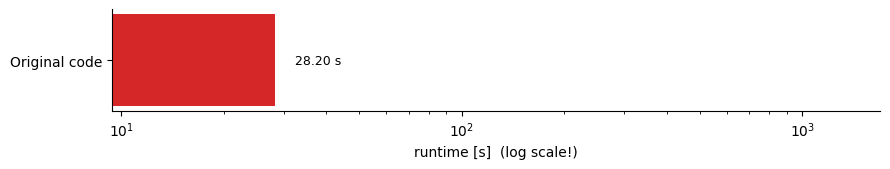

In [19]:
run_step("Original code", pipeline_original)

**5b — Fix 1: read the file once.** Move `load_sequences` out of the loop. 🎯 How much faster?

Fix 1: read the file once: 1.55 s   ✅ results identical to the first version


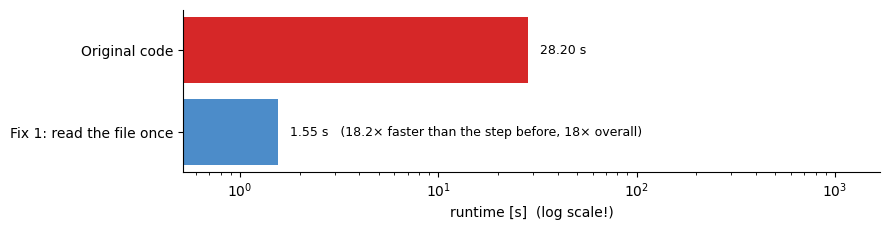

In [20]:
def pipeline_load_once(path, out):
    sequences = load_sequences(path)                      # read the file ONCE
    save_table({i: {} for i in sequences}, out)
    for name, feature in FEATURES.items():
        table = load_table(out)
        for seq_id in sequences:
            seq = clean(sequences[seq_id])
            table[seq_id][name] = feature(seq)
        save_table(table, out)


run_step("Fix 1: read the file once", pipeline_load_once)

<details>
<summary>🔍 What happened</summary>

By far the biggest win — more than 10×. The original re-read the file once per sequence and feature, so its runtime grows with the **square** of the number of sequences. Doubling the data would make it 4× slower. Repeated loading is the most common beginner mistake in analysis scripts.

</details>

**5c — Fix 2: clean each sequence once.** The cleaned sequence is the same for all four features.

Fix 2: clean each sequence once: 1.72 s   ✅ results identical to the first version


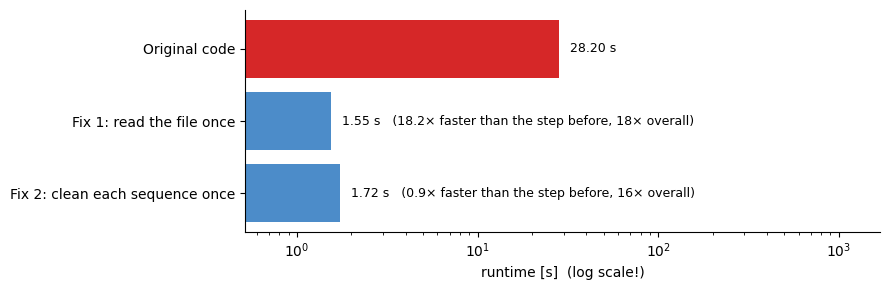

In [21]:
def pipeline_clean_once(path, out):
    sequences = load_sequences(path)
    cleaned = {i: clean(s) for i, s in sequences.items()}   # clean each sequence ONCE
    save_table({i: {} for i in cleaned}, out)
    for name, feature in FEATURES.items():
        table = load_table(out)
        for seq_id, seq in cleaned.items():
            table[seq_id][name] = feature(seq)
        save_table(table, out)


run_step("Fix 2: clean each sequence once", pipeline_clean_once)

<details>
<summary>🔍 What happened</summary>

Smaller gain — cleaning was done 4× and is now done 1×. *Never compute the same thing twice*: calculate once, store it, reuse it.

</details>

**5d — Fix 3: write the results once.** Keep the table in memory; save it at the end. 🎯 This one is tiny here. Why might it still matter on a cluster?

Fix 3: write the results once: 0.97 s   ✅ results identical to the first version


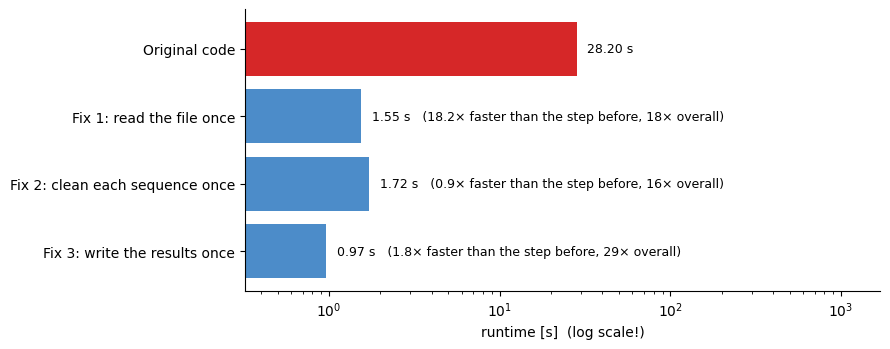

In [22]:
def pipeline_write_once(path, out, clean=clean, features=FEATURES):
    sequences = load_sequences(path)
    cleaned = {i: clean(s) for i, s in sequences.items()}
    table = {i: {} for i in cleaned}                        # keep results in memory ...
    for name, feature in features.items():
        for seq_id, seq in cleaned.items():
            table[seq_id][name] = feature(seq)
    save_table(table, out)                                  # ... and write ONCE at the end


run_step("Fix 3: write the results once", pipeline_write_once)

<details>
<summary>🔍 What happened</summary>

Almost no gain on this small file and local disk. On a cluster it is a different story: results often go to a **shared network file system** used by hundreds of users, where every open/write/read costs much more than on your laptop, and many jobs doing it at once slow everybody down. Writing and re-reading intermediate files is wasted I/O (and I/O costs energy, too).

</details>

**5e — Fix 4: built-in functions instead of loops.** Python loops over characters are slow; `str.count` and regular expressions run in fast compiled code. *The results must stay identical — look for the ✅.*

Fix 4: built-in functions instead of loops: 0.64 s   ✅ results identical to the first version


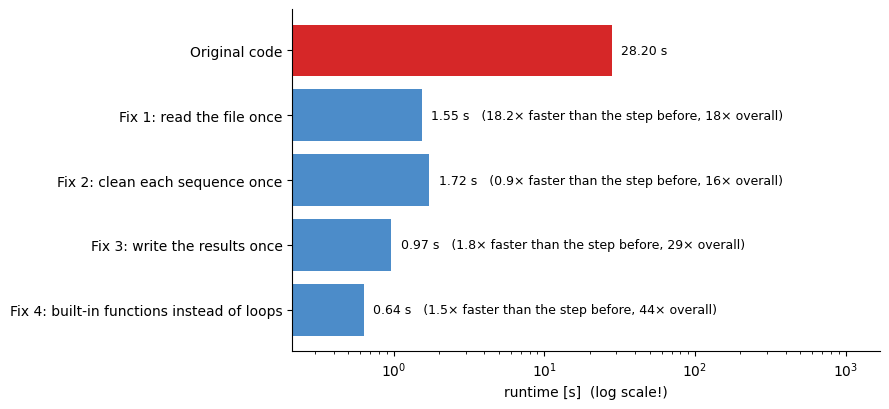

In [23]:
def clean_fast(seq):
    return re.sub("[^ACGT]", "", seq.upper())


def gc_content_fast(seq):
    return (seq.count("G") + seq.count("C")) / len(seq)


def cpg_count_fast(seq):
    return seq.count("CG")


def tata_count_fast(seq):
    return len(re.findall("(?=TATA)", seq))              # (?=...) also counts overlapping matches


def longest_run_fast(seq):
    return max(len(m.group()) for m in re.finditer(r"(.)\1*", seq))


FEATURES_FAST = {"gc_content": gc_content_fast, "cpg_count": cpg_count_fast,
                 "tata_count": tata_count_fast, "longest_run": longest_run_fast}

run_step("Fix 4: built-in functions instead of loops", pipeline_write_once, clean=clean_fast, features=FEATURES_FAST)

<details>
<summary>🔍 What happened</summary>

Another 2× or so from simply using what the language offers. In real projects, this is the step "use a library": NumPy, pandas, Biopython and friends are fast because their inner loops are compiled code.
The ✅ shows that we did not trade correctness for speed. Always keep a check like this when you optimise.

</details>

**5f — Fix 5: only now use more cores.** The code is lean: 500 sequences take a fraction of a second. Real data sets are much bigger, so let us use **6000 sequences** and spread them over workers — one task per sequence, because they are independent (Part 1 and Part 3!).
🎯 Colab has 2 cores. What speedup do you expect?

In [24]:
def one_sequence(seq):
    seq = clean_fast(seq)
    return {name: feature(seq) for name, feature in FEATURES_FAST.items()}


def pipeline_parallel(path, out, workers=2):
    sequences = load_sequences(path)
    if workers == 1:
        rows = list(map(one_sequence, sequences.values()))
    else:
        with get_context("fork").Pool(workers) as pool:
            rows = pool.map(one_sequence, sequences.values(), chunksize=200)
    save_table(dict(zip(sequences, rows)), out)


compare_workers(pipeline_parallel, workers=(1, 2), n_seqs=6000)

6,000 sequences, this machine has 2 cores

  1 worker(s):  7.41 s   speedup 1.00x   ✅
  2 worker(s):  7.78 s   speedup 0.95x   ✅


<details>
<summary>🔍 What happened</summary>

About 1.8–1.9× on 2 cores (Part 2: communication and the serial parts — here loading and saving — keep it below 2×).
This only paid off because we **first** made each piece of work cheap and **then** gave the workers enough of it (Part 1b: with tiny files, starting workers does not pay off).

</details>

### The punchline: what would a real data set cost?

A real sequencing run can have a million sequences. We measure the original code on a few small files, extrapolate, and compare it with the fixed code — and with throwing **128 cores** at each. (This runs the original on a few small files, ≈ 10–30 s.)

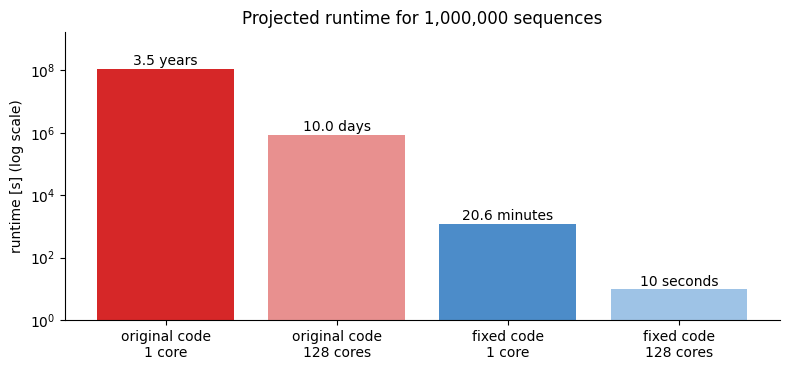

(projection: the original code grows with the SQUARE of the number of sequences, the fixed code linearly;
 the 128-core bars assume perfect speedup, which Part 2 told us is optimistic.)


In [25]:
scale_up_plot(pipeline_original)

<details>
<summary>🔍 Something to notice</summary>

The **original code on 128 cores** still takes days, while the **fixed code on one core** takes minutes. More hardware cannot rescue code that wastes its time — and every wasted hour on a cluster is wasted energy and queue time for others (E = P × t).
128 cores on the fixed code looks great, but that bar assumes perfect speedup; Part 2 showed reality is lower.

</details>

**In short — the order of attack:**
1. **Measure** before you change anything. Do not guess where the time goes.
2. **Stop repeating work:** load once, compute once, write once.
3. **Use built-ins and libraries** instead of hand-written loops.
4. **Check that the results are unchanged** after every change.
5. **Only then** parallelise and ask for more cores/nodes — and use Parts 2–4 to choose how.

---
## Wrap-up

| You saw | Rule of thumb |
|---|---|
| Speedup is limited by the serial part and by communication | Run a **small scaling test** before the big job |
| Efficiency drops as cores increase | Pick cores at **≥ 70 % efficiency**, not at the maximum speedup |
| Uneven work leaves workers idle | Use **dynamic** distribution; pick sensible chunk sizes |
| The queue plays Tetris | **Honest walltime + right-sized request** = shorter wait for you *and* others |
| Time = energy | **Better code** first, more cores second |
| Wasteful code can cost more than a bad queue | **Measure, stop repeating work, use built-ins — then parallelise** |

**Take-home ideas:** try other `workers=` values in Part 1 on your own laptop · estimate the CO₂ of your runs with [CodeCarbon](https://codecarbon.io/).